# 🎓 第6章 第1课：p-hacking 与因子动物园

**本节目标**：亲手模拟“数据窥探”如何制造假因子，并理解发表偏差/因子动物园。

对应原书第6章前半部分。

1. 生成 1000 个**纯噪声**因子，看 |t|>2 / 3 / 3.4 能挖出多少“显著因子”；
2. 模拟“挑最好区间发表”，看样本外衰减；
3. 认识因子动物园与因子大战。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.research import (
    simulate_random_factors, p_hacking_summary,
    publication_decay_experiment, polynomial_train_test_mse, sentiment_signal,
)
from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.sorting import long_short_factor, monotonicity_test
from factor_zero.statistics import factor_summary, nw_t_stat

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 1) 纯噪声里能挖出多少“显著因子”？

如果因子根本没有溢价，t 值应该围绕 0 波动。
但研究者会试很多因子、很多口径——只要试得够多，总能找到“显著”的。

下面生成 **1000 个纯噪声因子**，每个 120 期，计算均值的 t 值。

In [2]:
factors = simulate_random_factors(n_factors=1000, n_periods=120, seed=2020)
summary = p_hacking_summary(factors['t_stat'])
print('纯噪声因子的 t 值分布:')
print(factors['t_stat'].describe().round(3).to_dict())
summary.round(4)

纯噪声因子的 t 值分布:
{'count': 1000.0, 'mean': 0.017, 'std': 0.992, 'min': -3.361, '25%': -0.634, '50%': 0.004, '75%': 0.691, 'max': 3.582}


,threshold,count,share
0,2.0,45,0.045
1,3.0,3,0.003
2,3.4,1,0.001


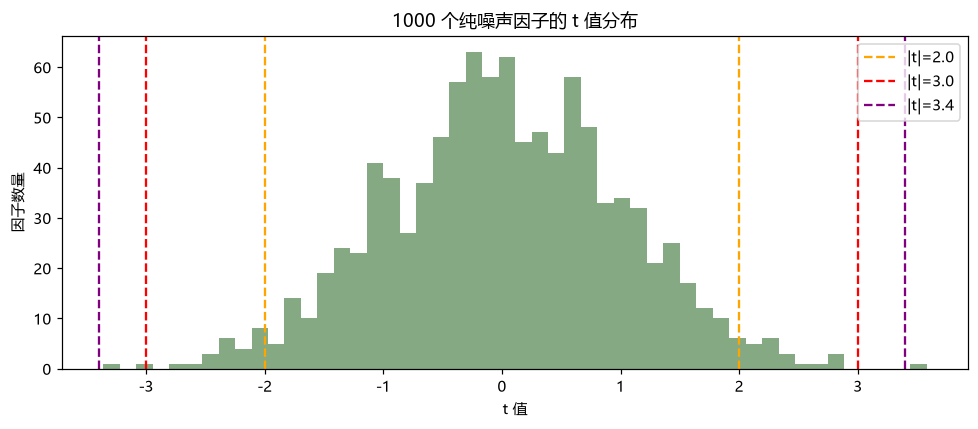

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(factors['t_stat'], bins=50, alpha=.75, color='#5B8C5A')
for thr, color in [(2.0, 'orange'), (3.0, 'red'), (3.4, 'purple')]:
    ax.axvline(thr, color=color, ls='--', label=f'|t|={thr}')
    ax.axvline(-thr, color=color, ls='--')
ax.set_xlabel('t 值'); ax.set_ylabel('因子数量')
ax.set_title('1000 个纯噪声因子的 t 值分布')
ax.legend(); plt.tight_layout(); plt.show()

### 三个门槛的含义

- **|t| > 2.0**：传统 5% 显著；1000 个噪声里约 5% 会“显著”（约 50 个）；
- **|t| > 3.0**：Harvey et al. (2016) 建议，应对多重检验；
- **|t| > 3.4**：Chordia et al. (2020) 更严格的门槛。

> 关键不是“t 值大不大”，而是**你试了多少次**。试得越多，假阳性越多。

## 2) 发表偏差：挑最好区间发表，样本外会怎样？

模拟：真实月均溢价 0.4%，噪声 3%，共 240 个月。
研究者挑“表现最好的 60 个月”发表；我们看全样本（长期真相）相对发表前衰减多少。
重复 500 次，看平均衰减。

In [4]:
decay = publication_decay_experiment(n_simulations=500, true_premium=0.004, noise=0.03, seed=7)
print(f'发表前月均（中位数）: {decay["in_sample"].median()*100:.3f}%')
print(f'全样本月均（中位数）: {decay["full_sample"].median()*100:.3f}%')
print(f'衰减中位数: {decay["decay"].median()*100:.1f}%')
print(f'衰减均值:   {decay["decay"].mean()*100:.1f}%')
decay[['in_sample','full_sample','decay']].describe().round(4)

发表前月均（中位数）: 1.010%
全样本月均（中位数）: 0.398%
衰减中位数: 61.4%
衰减均值:   63.0%


,in_sample,full_sample,decay
count,500.0000,500.0000,500.0000
mean,0.0103,0.0040,0.6296
std,0.0028,0.0020,0.1798
min,0.0017,-0.0024,0.2584
25%,0.0084,0.0026,0.5110
50%,0.0101,0.0040,0.6136
75%,0.0120,0.0055,0.7095
max,0.0174,0.0099,2.4089


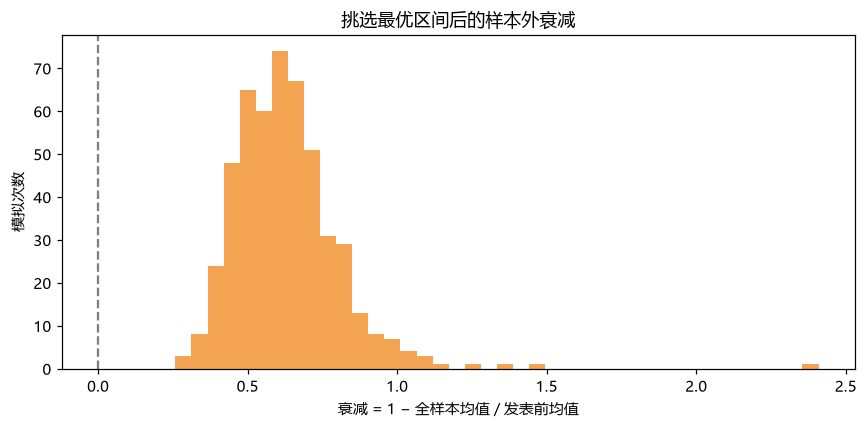

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(decay['decay'].dropna(), bins=40, color='#F28C28', alpha=.8)
ax.axvline(0, color='gray', ls='--')
ax.set_xlabel('衰减 = 1 − 全样本均值 / 发表前均值')
ax.set_ylabel('模拟次数')
ax.set_title('挑选最优区间后的样本外衰减')
plt.tight_layout(); plt.show()

## 3) 因子动物园与因子大战

| 时间/研究 | 结论 |
|---|---|
| Cochrane (2011) | 学术界的“因子动物园”：已挖出 400+ 因子 |
| Harvey et al. (2016) | 多重检验下，t 门槛应从 2.0 提高到 3.0 |
| Chordia et al. (2020) | 进一步建议 t > 3.4 |
| McLean & Pontiff (2016) | 因子发表后收益平均衰减 50%+ |

**因子大战**：不同研究互相“打架”——同一因子在不同样本、口径、区间下结论不同。
这不是坏事：它逼着研究者做样本外、稳健性和经济逻辑检验。

> 读论文时先问三件事：**样本外还活着吗？换了口径还成立吗？有经济逻辑吗？**

## ✋ 试一试

1. 把因子数量从 1000 改成 5000，|t|>2 的“显著因子”数量怎么变？
2. 把噪声从 0.03 改成 0.01，发表后衰减会更严重还是更轻？
3. 把 `in_sample` 从 60 改成 12，衰减怎么变？

## ✅ 本节小结

- 纯噪声里也能挖出“显著因子”，试得越多假阳性越多；
- 挑选最优区间发表，会高估因子收益，样本外衰减；
- 因子动物园/因子大战要求更高的 t 门槛、样本外和稳健性；
- 不要只看“显著”，要看“试了多少次、是否样本外、是否有逻辑”。

> 下一课：行为金融——投资者情绪与过度反应。